In [1]:
import pandas as pd
import  matplotlib.pyplot as plt
import seaborn as sns
import  numpy as np
from scipy import stats
import warnings
warnings.filterwarnings('ignore')
from sklearn.feature_selection import mutual_info_regression

pd.set_option('display.max_columns', None)
pd.set_option("display.max_rows", None)
pd.set_option('display.float_format', '{:,.0f}'.format)

In [2]:
## guarantor occupation, loan_use_sources
## should we train a model like lgbm or xgboost as those works better on NULL values to continued all dataset together A & B
# Use two different model for A and B, Cycle -1 dataset and cycle 2+ dataset then predict differently
# for cycle one dataset we want to take cycle = 1

# label Issue

""" label could be 10k to 5000k
Log transform the label
y = np.log1p(df["loan_amount"])
# train on y, then convert back:
pred_amount = np.expm1(model.predict(X))

Predict growth instead of the amount

y = np.log(df["loan_amount"] / df["prev_loan_amount"])   # log growth ratio
pred_amount = df["prev_loan_amount"] * np.exp(model.predict(X))

"""

' label could be 10k to 5000k\nLog transform the label\ny = np.log1p(df["loan_amount"])\n# train on y, then convert back:\npred_amount = np.expm1(model.predict(X))\n\nPredict growth instead of the amount\n\ny = np.log(df["loan_amount"] / df["prev_loan_amount"])   # log growth ratio\npred_amount = df["prev_loan_amount"] * np.exp(model.predict(X))\n\n'

In [2]:
df = pd.read_csv('loan_amount_prediction.csv')
df.head()

,member_id,name,dateofbirth,gender,current_addr_district,current_addr_thana,maritial_status,admission_date,education,occupation,alternative_occupation,total_family_member,total_earning_member,total_monthly_income,yearly_total_income,yearly_total_expenses,yearly_total_savings,home_owner_type,year_of_rent,farm_land_amt,prev_cycle_no,prev_loan_amount,loan_id,approvers_designation,proposer_oldid,approvers_id,loan_cycle_no,loan_Component,loan_use_sources,applied_loan_amount,loan_amount,last3_avg_loan_amount,prev_loan_inactive_date,disbursed_date,inactive_date,schedule_start_date,schedule_end_date,last_paid_date,installmenttype,totalInstallmentcount,transaction_count,paymentdaycount,schedule_max_days_late,total_savings_transactions,refund_amount,deposit_amount,installment_1,installment_2,installment_3,installment_4,installment_5,installment_6,installment_7,installment_8,installment_9,installment_10,installment_11,installment_12,installment_13,installment_14,installment_15,installment_16,installment_17,installment_18,installment_19,installment_20,installment_21,installment_22,installment_23,installment_24,installment_25,installment_26,installment_27,installment_28,installment_29,installment_30,installment_31,installment_32,installment_33,installment_34,installment_35,installment_36,installment_37,installment_38,installment_39,installment_40,installment_41,installment_42,installment_43,installment_44,installment_45,installment_46,installment_47,installment_48,installment_49,installment_50,installment_51,installment_52,installment_53,installment_54,installment_55,installment_56,installment_57,installment_58,installment_59,installment_60,installment_61,installment_62,installment_63,installment_64,installment_65,installment_66,installment_67,installment_68,installment_69,installment_70,installment_71,installment_72,installment_73,installment_74,installment_75,installment_76,installment_77,installment_78,installment_79,installment_80,installment_81,installment_82,installment_83,installment_84,installment_85,installment_86,installment_87,installment_88,installment_89,installment_90,installment_91
0,302095,Mst:Nasima Begum,1985-08-19,Female,Rangpur,Kaunia,Married,2019-05-06,Pre-Primary,Agriculture,krisi,3,1,"30,000","360,000","120,000","240,000",Own,0,8,7,"40,000",2235249,BM,01785393021,"136,410,218",8,JAGORON,Dairy Farm (ডেইরী ফার্ম/গাভী পালন),"40,000","40,000","53,333",2026-06-15,2026-06-17,2026-06-29,2026-07-01,2027-05-12,2026-06-29,Weekly,46,46,1,0,1,0,50,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1339749,NAJMA BEGUM,1984-01-01,Female,Bhola,Bhola Sadar,Married,2026-06-03,Secondary,Housewife,NaN,4,2,"100,000","1,200,000","450,000","750,000",Own,0,50,NaN,NaN,2219692,SM & AM,ID Nai,"40,151,207",1,JAGORON,Dairy Farm (ডেইরী ফার্ম/গাভী পালন),"90,000","90,000",NaN,NaN,2026-06-08,2026-06-29,2026-07-12,2027-06-13,2026-06-29,Mounthly,12,13,2,0,1,"4,600",0,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,advanced,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1137258,Mohammad Mofiz,1968-05-10,Male,Bhola,Borhanuddin,Married,2025-05-07,Higher-Secondary,Business,Business,5,2,"80,000","960,000"

In [3]:
df =df.drop(columns = [cols for cols in df.columns if cols.startswith('installment_')])
df.drop(columns=['prev_cycle_no', 'prev_loan_amount','approvers_designation', 'approvers_id','last3_avg_loan_amount',
       'prev_loan_inactive_date', 'disbursed_date', 'inactive_date',
       'schedule_start_date', 'schedule_end_date', 'last_paid_date', 'transaction_count',
       'paymentdaycount', 'schedule_max_days_late',
       'total_savings_transactions', 'refund_amount', 'deposit_amount'], inplace=True)
df.columns

Index(['member_id', 'name', 'dateofbirth', 'gender', 'current_addr_district',
       'current_addr_thana', 'maritial_status', 'admission_date', 'education',
       'occupation', 'alternative_occupation', 'total_family_member',
       'total_earning_member', 'total_monthly_income', 'yearly_total_income',
       'yearly_total_expenses', 'yearly_total_savings', 'home_owner_type',
       'year_of_rent', 'farm_land_amt', 'loan_id', 'proposer_oldid',
       'loan_cycle_no', 'loan_Component', 'loan_use_sources',
       'applied_loan_amount', 'loan_amount', 'installmenttype',
       'totalInstallmentcount'],
      dtype='object')

### Start Here

In [4]:
"""
applied loan_amount --
approval ratio -- 100   % always
applied_to_income


Target have special structure
5 values cover almost 60% of loans (50,100, 80, 40, 200)
15 values cover 95% and 120 distinct loan exist.
Skew is 5.7 and kurtosis is 86. The median is 60k and the mean is 104k, so the tail is heavy
AGROSOR is only ≈8% of members but ≈33% of the money disbursed (mean 405k). JAGORON and SUFOLON together are ≈90% of members, with means near 76k and a tight std of about 48k.
Check this with a stratified comparison or SHAP before treating gender as a driver.

---



# features
Demographics are weak. Women's median is 60k versus 95k for men, but men are probably concentrated in Business, AGROSOR and Immigrant loans.

skew and kurtosis --
if heavily right skew then mean is misleading and median is more relevant, so skew help us to take desition based on distribution not mean.
kurtosis define extreme value like an observation that is far away from center(mean) and extreme value cannot be the outlier
"""

"\napplied loan_amount --\napproval ratioc -- 100   % always\napplied_to_income\n\n\nTarget have special structure\n5 values cover almost 60% of loans (50,100, 80, 40, 200)\n15 values cover 95% and 120 distinct loan exist.\nSkew is 5.7 and kurtosis is 86. The median is 60k and the mean is 104k, so the tail is heavy\nAGROSOR is only ≈8% of members but ≈33% of the money disbursed (mean 405k). JAGORON and SUFOLON together are ≈90% of members, with means near 76k and a tight std of about 48k.\nCheck this with a stratified comparison or SHAP before treating gender as a driver.\n\n\n\n\n# features\nDemographics are weak. Women's median is 60k versus 95k for men, but men are probably concentrated in Business, AGROSOR and Immigrant loans.\n\nskew and kurtosis --\nif heavily right skew then mean is misleading and median is more relevant, so skew help us to take desition based on distribution not mean.\nkurtosis define extreme value like an observation that is far away from center(mean) and extr

In [5]:
df=df[df['loan_cycle_no']==1].copy()
df.head()

,member_id,name,dateofbirth,gender,current_addr_district,current_addr_thana,maritial_status,admission_date,education,occupation,alternative_occupation,total_family_member,total_earning_member,total_monthly_income,yearly_total_income,yearly_total_expenses,yearly_total_savings,home_owner_type,year_of_rent,farm_land_amt,loan_id,proposer_oldid,loan_cycle_no,loan_Component,loan_use_sources,applied_loan_amount,loan_amount,installmenttype,totalInstallmentcount
1,1339749,NAJMA BEGUM,1984-01-01,Female,Bhola,Bhola Sadar,Married,2026-06-03,Secondary,Housewife,NaN,4,2,"100,000","1,200,000","450,000","750,000",Own,0,50,2219692,ID Nai,1,JAGORON,Dairy Farm (ডেইরী ফার্ম/গাভী পালন),"90,000","90,000",Mounthly,12
4,1336203,SABINA KHATUN,1996-08-04,Female,Faridpur,Modhukhali,Married,2026-05-17,Pre-Primary,Housewife,NaN,4,1,"40,000","480,000","320,000","160,000",Own,0,90,2210543,01569126132,1,SUFOLON,Jute cultivation (পাট চাষ),"80,000","80,000",Mounthly,12
5,1335120,RAHIMA AKTER,1988-11-10,Female,Shariatpur,Damuddya,Married,2026-05-14,Pre-Primary,Housewife,NaN,5,1,"450,000","5,400,000","400,000","5,000,000",Own,0,10,2203667,01751090505,1,JAGORON,Dairy Farm (ডেইরী ফার্ম/গাভী পালন),"200,000","200,000",Mounthly,12
6,872455,Mst Forida khatun,1982-03-25,Female,Meherpur,Meherpur,Married,2026-05-11,Primary,Housewife,NaN,4,2,"80,000","960,000","500,000","460,000",Own,0,20,2205405,0187240723,1,JAGORON,Banana Cultivation (কলা চাষ),"200,000","200,000",Weekly,46
9,1269453,Md Shahinur Islam,1982-03-19,Male,Dinajpur,Ghoraghat,Married,2026-01-01,Pre-Primary,Business,NaN,3,1,"30,000","360,000","144,000","216,000",Own,0,200,2200795,55060708,1,JAGORON,Dairy Farm (ডেইরী ফার্ম/গাভী পালন),"200,000","200,000",Mounthly,12


In [6]:
 # df.to_csv('SingleCycleLoaneeMember.csv', index=False, encoding='utf-8-sig')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 123993 entries, 1 to 299999
Data columns (total 29 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   member_id               123993 non-null  int64  
 1   name                    123993 non-null  object 
 2   dateofbirth             123993 non-null  object 
 3   gender                  123993 non-null  object 
 4   current_addr_district   123993 non-null  object 
 5   current_addr_thana      123993 non-null  object 
 6   maritial_status         123993 non-null  object 
 7   admission_date          123993 non-null  object 
 8   education               123993 non-null  object 
 9   occupation              123993 non-null  object 
 10  alternative_occupation  43248 non-null   object 
 11  total_family_member     123993 non-null  int64  
 12  total_earning_member    123993 non-null  int64  
 13  total_monthly_income    123993 non-null  float64
 14  yearly_total_income     1

In [7]:
miss = pd.DataFrame({"missing": df.isna().sum(), "pct": df.isna().mean() * 100})
miss = miss[miss.missing > 0].sort_values("pct", ascending=False)
print(miss if len(miss) else "No missing values")

                        missing  pct
alternative_occupation    80745   65
home_owner_type           31055   25
proposer_oldid             3995    3
year_of_rent                 14    0


In [8]:
dup_members = df["member_id"].duplicated().sum()
dup_members

np.int64(0)

In [9]:
print("Fully duplicated rows:", df.duplicated().sum())

Fully duplicated rows: 0


In [10]:
ID_COLS = ["member_id", "name", "proposer_oldid"]
num_cols = df.select_dtypes(include=np.number).columns.drop('loan_amount').tolist()
cat_cols = [c for c in df.select_dtypes(include=["object", "category"]).columns
            if c not in ID_COLS]

In [11]:
df['dateofbirth'] = pd.to_datetime(df['dateofbirth'])
df['admission_date'] = pd.to_datetime(df['admission_date'])

df['age_at_admission'] = (df['admission_date']- df['dateofbirth']).dt.days//365
df["admission_year"] = df["admission_date"].dt.year
df["admission_month"] = df["admission_date"].dt.month

In [12]:
# lowest amount
df.loc[df['loan_amount'].idxmin()][['loan_amount', 'member_id']]

loan_amount     4,000
member_id      472009
Name: 51970, dtype: object

In [13]:
# Highest loan
df.loc[df['loan_amount'].idxmax()][['loan_amount', 'member_id']]

loan_amount   5,000,000
member_id       1154781
Name: 62754, dtype: object

In [14]:
# gender number and percentage
pd.DataFrame({
   'values': df['gender'].value_counts(),
    'percentage': df['gender'].value_counts(normalize=True).mul(100).round(2)
})

,values,percentage
gender,,
Female,111112,90
Male,12881,10


In [15]:
# maritial status
df['maritial_status'].value_counts()

maritial_status
Married      121592
Single         1079
Unmarried      1040
Widowed         233
Divorced         49
Name: count, dtype: int64

In [16]:
# educational number and percentage
pd.DataFrame({
    'value' : df['education'].value_counts(),
    'percentage' : df['education'].value_counts(normalize=True).mul(100).round(2)
})

,value,percentage
education,,
Pre-Primary,60751,49
Primary,31136,25
Secondary,16532,13
Higher-Secondary,3744,3
JSC,3503,3
SSC,2089,2
Graduation,1994,2
PSC,1930,2
HSC,878,1


In [17]:
# weekly and monthly
df['installmenttype'].value_counts()

installmenttype
Weekly      81073
Mounthly    42920
Name: count, dtype: int64

In [18]:
df['totalInstallmentcount'].value_counts()

totalInstallmentcount
46    80109
12    41579
0      1801
18      499
24        3
90        1
67        1
Name: count, dtype: int64

In [19]:
df[df['totalInstallmentcount']==24]

,member_id,name,dateofbirth,gender,current_addr_district,current_addr_thana,maritial_status,admission_date,education,occupation,alternative_occupation,total_family_member,total_earning_member,total_monthly_income,yearly_total_income,yearly_total_expenses,yearly_total_savings,home_owner_type,year_of_rent,farm_land_amt,loan_id,proposer_oldid,loan_cycle_no,loan_Component,loan_use_sources,applied_loan_amount,loan_amount,installmenttype,totalInstallmentcount,age_at_admission,admission_year,admission_month
15241,1192831,MD. Shamsun Nahar,1971-10-05,Female,Bogra,Kahaloo,Married,2025-08-12,Primary,Housewife,Agriculture,6,3,"80,000","960,000","300,000","660,000",Own,0,60,1874083,0040990108,1,JAGORON,Dairy Farm (ডেইরী ফার্ম/গাভী পালন),"100,000","100,000",Mounthly,24,53,2025,8
82068,384608,Nashima,1961-11-14,Female,Barishal,Gouranadi,Married,2017-01-15,SSC,Housewife,NaN,4,2,"75,000","900,000","260,000","700,000",NaN,0,0,1780954,01942228374,1,AGROSOR,Fishery (মাছের চাষ),"400,000","400,000",Mounthly,24,55,2017,1
283981,1036863,Mst Sahara Banu,1994-04-01,Female,Dinajpur,Birampur,Married,2024-11-18,Primary,Housewife,Agriculture,3,1,"25,000","300,000","150,000","150,000",NaN,0,0,1562161,83121110,1,JAGORON,Potato Cultivation (আলু চাষ),"40,000","40,000",Mounthly,24,30,2024,11


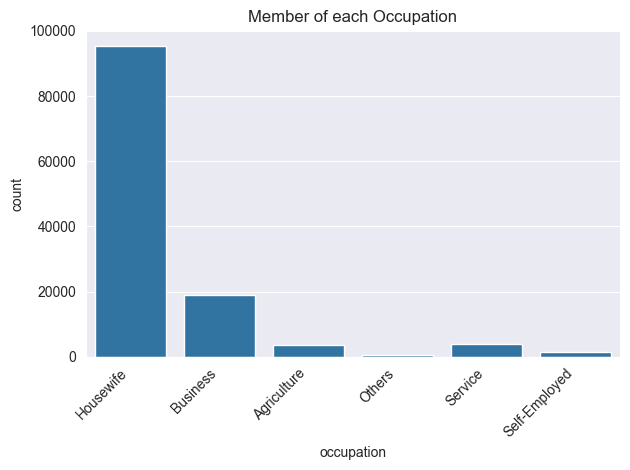

In [20]:
sns.countplot(data=df, x='occupation')
plt.title('Member of each Occupation')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [21]:
df['alternative_occupation'].value_counts()

alternative_occupation
Agriculture                                                        10875
Business                                                            3992
Agriculture                                                         2102
Job                                                                 1785
Agricultural                                                        1125
Business                                                            1122
Krishi                                                               773
Housewife                                                            744
Krisi                                                                574
agriculture                                                          540
Housewife                                                            539
Krishi                                                               446
Service                                                              406
Probasi                     

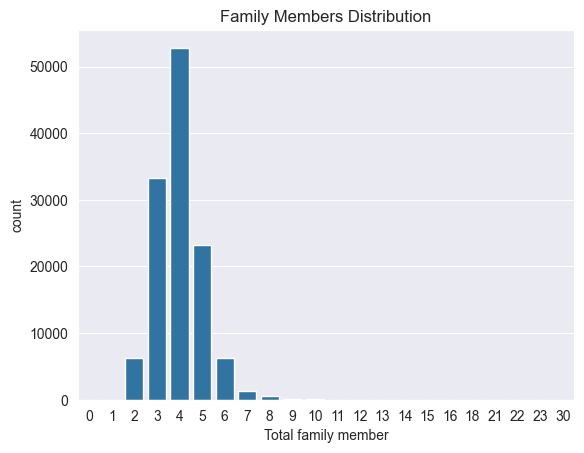

In [22]:
sns.countplot(data=df, x='total_family_member')
plt.xlabel('Total family member')
plt.title('Family Members Distribution')
plt.show()

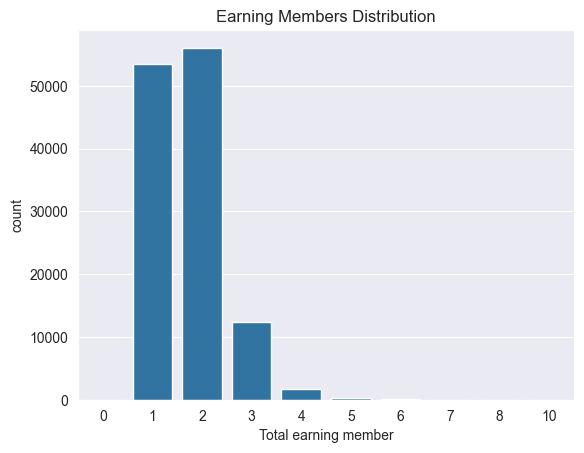

In [58]:
sns.countplot(data=df, x='total_earning_member')
plt.xlabel('Total earning member')
plt.title('Earning Members Distribution')
plt.show()

In [65]:
df['total_monthly_income'].value_counts()

total_monthly_income
50000.0        20989
40000.0        18111
30000.0        17278
60000.0        10799
70000.0         6661
35000.0         5771
25000.0         5231
80000.0         5228
45000.0         4052
20000.0         3880
100000.0        3067
90000.0         2386
55000.0         1915
120000.0        1349
150000.0        1136
65000.0         1106
200000.0         798
75000.0          748
110000.0         623
300000.0         590
15000.0          480
250000.0         459
130000.0         433
85000.0          428
500000.0         361
32000.0          339
600000.0         303
140000.0         302
42000.0          264
180000.0         257
360000.0         252
95000.0          249
350000.0         245
36000.0          241
400000.0         228
160000.0         213
170000.0         210
31000.0          190
27000.0          181
22000.0          175
26000.0          160
38000.0          157
28000.0          156
48000.0          156
450000.0         141
41000.0          139
220000.0     

In [23]:
df["income_per_member"] = df["total_monthly_income"] / df["total_family_member"].replace(0, np.nan)
df["income_per_earner"] = df["total_monthly_income"] / df["total_earning_member"].replace(0, np.nan)
df["earner_ratio"] = (
    df["total_earning_member"]
    / df["total_family_member"].replace(0, np.nan)
).astype(float) *100
df["savings_rate"] = df["yearly_total_savings"] / df["yearly_total_income"].replace(0, np.nan).astype(float) * 100
df["applied_to_income"] = df["applied_loan_amount"] / df["yearly_total_income"].replace(0, np.nan).astype(float) * 100
df["approval_ratio"] = df['loan_amount'] / df["applied_loan_amount"].replace(0, np.nan).astype(float) * 100


df[['member_id', 'income_per_member', 'income_per_earner','earner_ratio', 'savings_rate', 'applied_to_income', 'approval_ratio']].head(10)

,member_id,income_per_member,income_per_earner,earner_ratio,savings_rate,applied_to_income,approval_ratio
1,1339749,"25,000","50,000",50,62,8,100
4,1336203,"10,000","40,000",25,33,17,100
5,1335120,"90,000","450,000",20,93,4,100
6,872455,"20,000","40,000",50,48,21,100
9,1269453,"10,000","30,000",33,60,56,100
14,1332960,"13,333","40,000",33,69,17,100
19,1325151,"12,500","25,000",50,40,13,100
20,1318197,"16,667","25,000",67,20,17,100
21,1319962,"10,000","30,000",33,44,8,100
27,1320038,"16,667","50,000",33,50,8,100


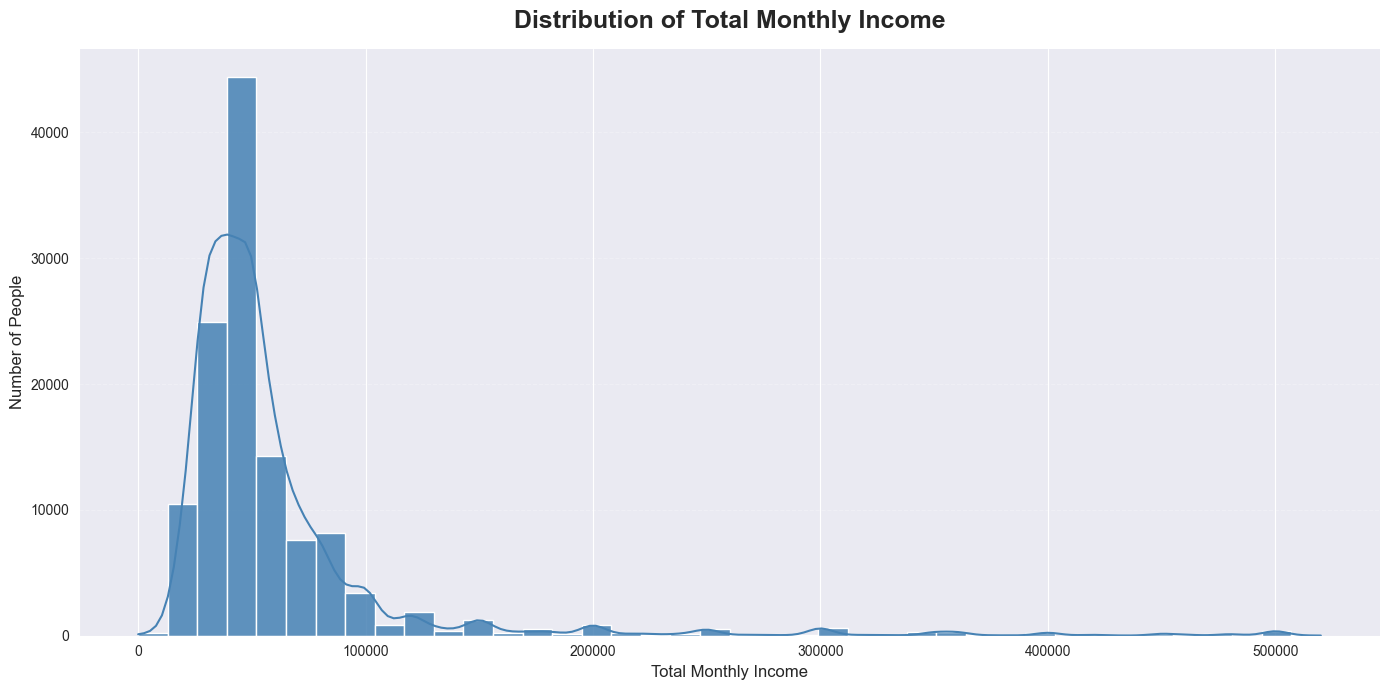

In [14]:
income = df['total_monthly_income'].dropna()
income = income[income > 0]

# Dynamically determine the 99th percentile
upper_limit = income.quantile(0.99)

# Keep values within the 99th percentile for visualization
income_plot = income[income <= upper_limit]

plt.figure(figsize=(14, 7))

sns.histplot(
    income_plot,
    bins=40,
    kde=True,
    color='steelblue',
    edgecolor='white',
    alpha=0.85
)

plt.title(
    'Distribution of Total Monthly Income',
    fontsize=18,
    fontweight='bold',
    pad=15
)

plt.xlabel('Total Monthly Income', fontsize=12)
plt.ylabel('Number of People', fontsize=12)

# Format x-axis with commas
plt.ticklabel_format(style='plain', axis='x')

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.25
)

sns.despine()

plt.tight_layout()
plt.show()

# print(f"99th percentile: {upper_limit:,.0f}")
# print(f"Excluded values: {(income > upper_limit).sum():,}")

In [45]:
df[df['total_family_member']==30]

,member_id,name,dateofbirth,gender,current_addr_district,current_addr_thana,maritial_status,admission_date,education,occupation,alternative_occupation,total_family_member,total_earning_member,total_monthly_income,yearly_total_income,yearly_total_expenses,yearly_total_savings,home_owner_type,year_of_rent,farm_land_amt,proposer_oldid,loan_cycle_no,loan_Component,loan_use_sources,applied_loan_amount,loan_amount
295533,1033654,Moriom Akthar Rojina,2001-05-16,Female,Mymensingh,Trishal,Married,2024-11-14,Pre-Primary,Housewife,Foreigner,30,2,70000.0,840000.0,240000.0,600000.0,Own,0,40,01761809096,1,SUFOLON,Dairy Farm (ডেইরী ফার্ম/গাভী পালন),50000.0,50000.0


In [16]:
df['current_addr_district'].value_counts()

current_addr_district
Chattogram         9096
Dinajpur           6903
Brahmanbaria       6052
Bhola              5755
Mymensingh         5613
Rajshahi           4287
Patuakhali         4162
Barishal           3657
Rangpur            3533
Jashore            3295
Gazipur            3282
Coxs Bazar         3011
Comilla            2956
Dhaka              2933
Jhenaidah          2739
Kishoreganj        2739
Sunamgonj          2489
Khagrachhari       2294
Chuadanga          2079
Chapainawabgonj    1958
Natore             1956
Faridpur           1940
Naogaon            1918
Barguna            1742
Netrokona          1732
Nilphamari         1711
Magura             1692
Bogra              1685
Gopalgonj          1672
Lalmonirhat        1603
Jamalpur           1542
Kushtia            1508
Narsingdi          1495
Pirojpur           1447
Joypurhat          1329
Habiganj           1305
Gaibandha          1295
Munshiganj         1292
Sylhet             1271
Meherpur           1266
Shariatpur        

In [28]:
df['loan_use_sources'].value_counts()

loan_use_sources
Dairy Farm (ডেইরী ফার্ম/গাভী পালন)                                                                      30277
Paddy Cultivation (ধান চাষ)                                                                             21196
Fishery (মাছের চাষ)                                                                                      6257
Auto Purchases                                                                                           6215
Immigrant Loan (প্রবাসী ঋণ)                                                                              5440
Vegetable Cultivation (শাক সবজী চাষ)                                                                     5048
Goru Motataja Koron (গরু মোটাতাজা করন)                                                                   4322
Grocery Business (মুদি ব্যবসা)                                                                           3860
Poultry Farming (হাঁস-মুরগি পালন)                                                                      

In [25]:
df.groupby('loan_use_sources').agg(
    Value = ('loan_use_sources', 'size'),
    percentage = ('loan_use_sources', lambda x : len(x) / len(df) * 100),
    total_loan_amount = ('loan_amount', 'sum'),
    min_loan_amount = ('loan_amount', 'min'),
    max_loan_amount = ('loan_amount', 'max'),
    avg_loan_amount = ('loan_amount', 'mean')

).sort_values(ascending=False, by = 'Value').head(10)



,Value,percentage,total_loan_amount,min_loan_amount,max_loan_amount,avg_loan_amount
loan_use_sources,,,,,,
Dairy Farm (ডেইরী ফার্ম/গাভী পালন),30277,24,"2,706,320,000","5,000","1,500,000","89,385"
Paddy Cultivation (ধান চাষ),21196,17,"1,586,891,000","5,000","1,000,000","74,867"
Fishery (মাছের চাষ),6257,5,"766,260,000","10,000","1,500,000","122,464"
Auto Purchases,6215,5,"428,706,000","10,000","800,000","68,979"
Immigrant Loan (প্রবাসী ঋণ),5440,4,"1,490,057,000","20,000","2,000,000","273,908"
Vegetable Cultivation (শাক সবজী চাষ),5048,4,"325,352,000","5,000","500,000","64,452"
Goru Motataja Koron (গরু মোটাতাজা করন),4322,3,"370,964,000","10,000","800,000","85,832"
Grocery Business (মুদি ব্যবসা),3860,3,"468,785,000","5,000","2,000,000","121,447"
Poultry Farming (হাঁস-মুরগি পালন),2715,2,"199,618,000","5,000","1,200,000","73,524"


In [40]:
df.groupby('loan_use_sources')['loan_amount'].agg(
    count='count',
    min='min',
    Q1=lambda x: x.quantile(.25),
    median='median',
    Q3=lambda x: x.quantile(.75),
    max='max',
    mean='mean'
).sort_values('count', ascending=False)

,count,min,Q1,median,Q3,max,mean
loan_use_sources,,,,,,,
Dairy Farm (ডেইরী ফার্ম/গাভী পালন),30277,"5,000","50,000","60,000","100,000","1,500,000","89,385"
Paddy Cultivation (ধান চাষ),21196,"5,000","50,000","50,000","90,000","1,000,000","74,867"
Fishery (মাছের চাষ),6257,"10,000","50,000","100,000","150,000","1,500,000","122,464"
Auto Purchases,6215,"10,000","50,000","50,000","80,000","800,000","68,979"
Immigrant Loan (প্রবাসী ঋণ),5440,"20,000","150,000","200,000","300,000","2,000,000","273,908"
Vegetable Cultivation (শাক সবজী চাষ),5048,"5,000","40,000","50,000","80,000","500,000","64,452"
Goru Motataja Koron (গরু মোটাতাজা করন),4322,"10,000","40,000","60,000","100,000","800,000","85,832"
Grocery Business (মুদি ব্যবসা),3860,"5,000","50,000","80,000","120,000","2,000,000","121,447"
Poultry Farming (হাঁস-মুরগি পালন),2715,"5,000","40,000","50,000","80,000","1,200,000","73,524"


### Target Analysis

In [18]:
y = df['loan_amount'].dropna()
print(y.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

count     123,993
mean      103,887
std       119,210
min         4,000
1%         20,000
5%         30,000
25%        50,000
50%        60,000
75%       100,000
95%       300,000
99%       500,000
max     5,000,000
Name: loan_amount, dtype: float64


In [19]:
print("Skew:", round(y.skew(), 3), " Kurtosis:", round(y.kurt(), 3))

Skew: 5.688  Kurtosis: 85.994


In [20]:
print("Most common values:\n", y.value_counts().head(15))

Most common values:
 loan_amount
50,000     28495
100,000    14230
80,000     11325
40,000     10741
200,000     8997
60,000      8860
30,000      7873
300,000     6550
70,000      6224
150,000     5006
20,000      3803
90,000      2468
500,000     2124
400,000      890
120,000      740
Name: count, dtype: int64


In [21]:
print("Unique values:", y.nunique(), "(few unique values => consider classification/ordinal)")

Unique values: 120 (few unique values => consider classification/ordinal)


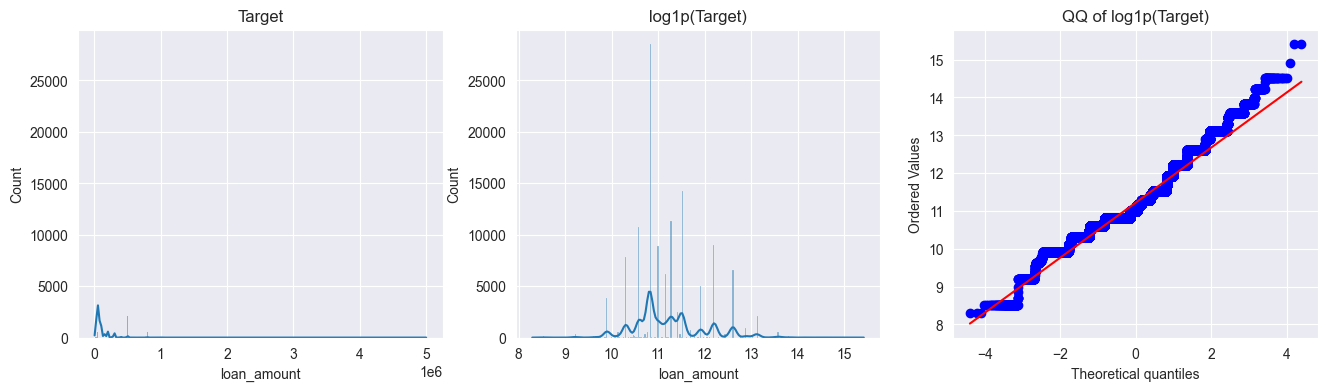

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(y, kde=True, ax=ax[0]); ax[0].set_title("Target")
sns.histplot(np.log1p(y), kde=True, ax=ax[1]); ax[1].set_title("log1p(Target)")
stats.probplot(np.log1p(y), plot=ax[2]); ax[2].set_title("QQ of log1p(Target)")
if "admission_year" in df:
    plt.figure(figsize=(10, 4))
    df.groupby("admission_year")['loan_amount'].agg(["mean", "median"]).plot(marker="o")
    plt.title("First loan amount by admission year (policy drift / inflation)")

In [25]:
# Numeric Summary and Outlier (IQR) Rule Analysis)
rows = []
for c in num_cols:
    s = df[c].dropna()
    if s.empty:
        continue
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    out = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    rows.append([c, s.mean(), s.median(), s.std(), s.min(), s.max(), s.skew(), out, out / len(s) * 100])
summ = pd.DataFrame(rows, columns=["feature", "mean", "median", "std", "min", "max", "skew", "n_outliers", "pct_outliers"])
print(summ.round(2).to_string(index=False))

              feature      mean    median        std       min           max  skew  n_outliers  pct_outliers
            member_id 1,081,625 1,099,754    132,761       946     1,339,749    -5        5309             4
  total_family_member         4         4          1         0            30     1         336             0
 total_earning_member         2         2          1         0            10     1        2000             2
 total_monthly_income    76,418    50,000  1,453,162         0   500,001,554   330       13634            11
  yearly_total_income   917,016   600,000 17,437,949         0 6,000,018,648   330       13634            11
yearly_total_expenses   316,820   240,000    636,957         0    96,000,000    57        6642             5
 yearly_total_savings   557,472   300,000  3,637,224         0   935,500,000   159        9483             8
        farm_land_amt    20,710        10  6,129,803         0 2,147,483,647   347        8109             7
              loan_

In [17]:
# n = len(num_cols)
# cols = 4
# rws = int(np.ceil(n / cols))
# fig, axes = plt.subplots(rws, cols, figsize=(4.5 * cols, 3.2 * rws))
# for a, c in zip(axes.ravel(), num_cols):
#     sns.histplot(df[c].dropna(), kde=False, ax=a, bins=40)
#     a.set_title(c, fontsize=9)
# for a in axes.ravel()[n:]:
#     a.axis("off")
#
# fig, axes = plt.subplots(rws, cols, figsize=(4.5 * cols, 3 * rws))
# for a, c in zip(axes.ravel(), num_cols):
#     sns.boxplot(x=df[c], ax=a); a.set_title(c, fontsize=9)
# for a in axes.ravel()[n:]:
#     a.axis("off")

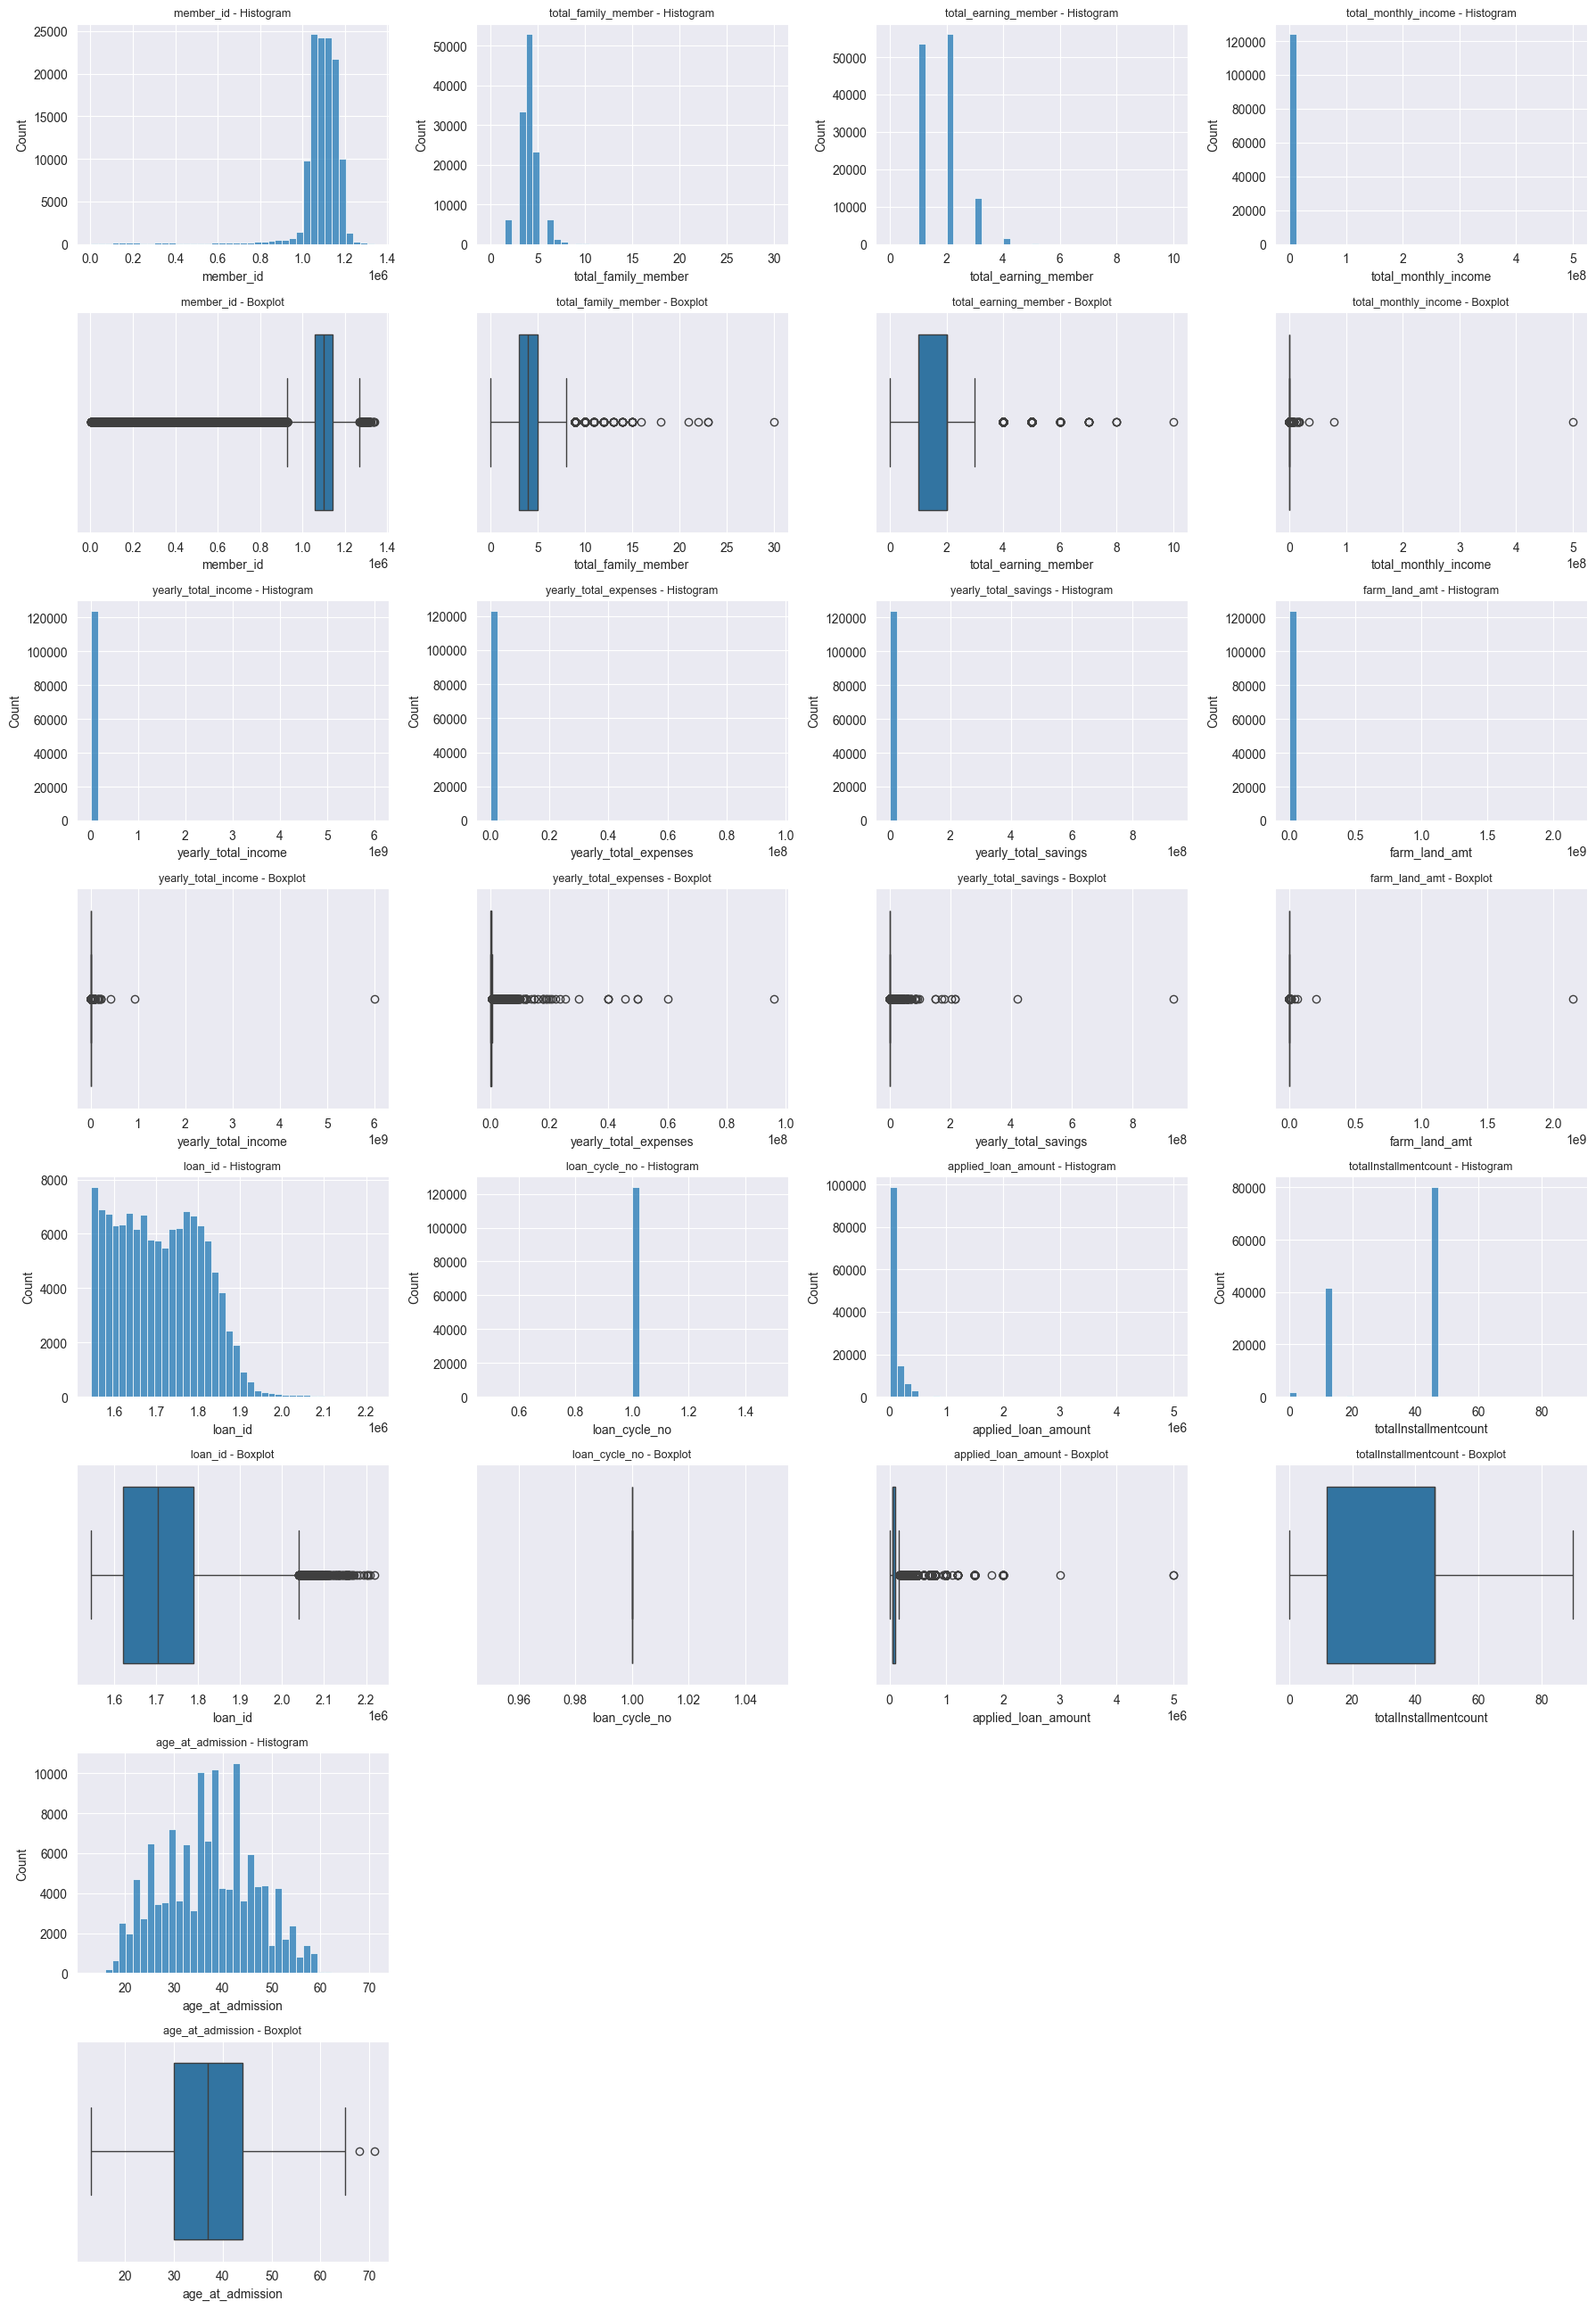

In [45]:
n = len(num_cols)
cols = 4
rws = int(np.ceil(n / cols))

fig, axes = plt.subplots(
    rws * 2, cols,
    figsize=(4.5 * cols, 6.5 * rws)
)

axes = axes.reshape(rws * 2, cols)

for i, c in enumerate(num_cols):
    col = i % cols
    row = (i // cols) * 2

    # Histogram
    sns.histplot(df[c].dropna(), kde=False, ax=axes[row, col], bins=40)
    axes[row, col].set_title(f"{c} - Histogram", fontsize=9)

    # Boxplot directly below
    sns.boxplot(x=df[c], ax=axes[row + 1, col])
    axes[row + 1, col].set_title(f"{c} - Boxplot", fontsize=9)

# Hide unused axes
for i in range(len(num_cols), rws * cols):
    col = i % cols
    row = (i // cols) * 2

    axes[row, col].axis("off")
    axes[row + 1, col].axis("off")

plt.tight_layout()
plt.show()



--- gender (unique=2) ---
gender
Female    111112
Male       12881
Name: count, dtype: int64
Rare levels (<1%): 0

--- current_addr_district (unique=64) ---
current_addr_district
Chattogram      9096
Dinajpur        6903
Brahmanbaria    6052
Bhola           5755
Mymensingh      5613
Rajshahi        4287
Patuakhali      4162
Barishal        3657
Rangpur         3533
Jashore         3295
Name: count, dtype: int64
Rare levels (<1%): 23

--- current_addr_thana (unique=437) ---
current_addr_thana
Gaffargaon     2023
Sreepur        1734
Bhola Sadar    1584
Patgram        1493
Rangunia       1351
Charfassion    1274
Mymensingh     1166
Borhanuddin    1131
Nabinagar      1046
Banshkhali     1033
Name: count, dtype: int64
Rare levels (<1%): 431

--- maritial_status (unique=5) ---
maritial_status
Married      121592
Single         1079
Unmarried      1040
Widowed         233
Divorced         49
Name: count, dtype: int64
Rare levels (<1%): 4

--- education (unique=17) ---
education
Pre-Primary  

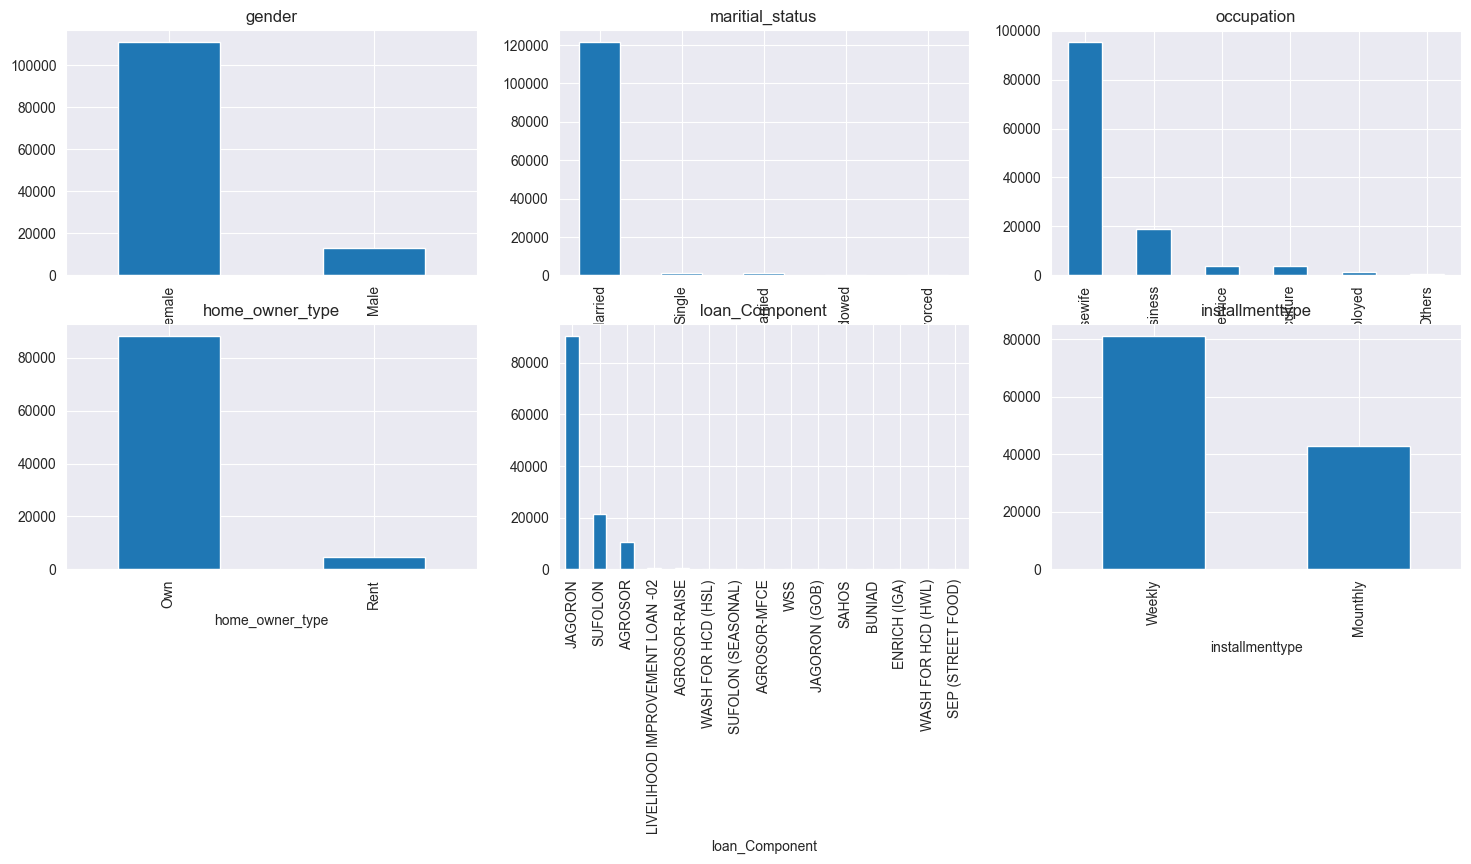

In [27]:
## Categorical Univariate
for c in cat_cols:
    vc = df[c].value_counts(dropna=False)
    print(f"\n--- {c} (unique={df[c].nunique()}) ---")
    print(vc.head(10))
    rare = (vc / len(df) < 0.01).sum()
    print(f"Rare levels (<1%): {rare}")

low_card = [c for c in cat_cols if df[c].nunique() <= 15]
if low_card:
    cols2 = 3
    r2 = int(np.ceil(len(low_card) / cols2))
    fig, axes = plt.subplots(r2, cols2, figsize=(6 * cols2, 3.5 * r2))
    for a, c in zip(np.array(axes).ravel(), low_card):
        df[c].value_counts().plot.bar(ax=a); a.set_title(c)
    for a in np.array(axes).ravel()[len(low_card):]:
        a.axis("off")

## SpearMan and Person Correlation

              feature  pearson  spearman
  applied_loan_amount        1         1
 total_monthly_income        0         1
  yearly_total_income        0         1
totalInstallmentcount       -0        -1
 yearly_total_savings        0         0
yearly_total_expenses        0         0
        farm_land_amt       -0         0
  total_family_member        0         0
 total_earning_member        0         0
     age_at_admission        0         0
            member_id        0         0
              loan_id        0         0

Mutual information with target:
 applied_loan_amount     3
yearly_total_income     0
total_monthly_income    0
totalInstallmentcount   0
yearly_total_savings    0
yearly_total_expenses   0
loan_id                 0
farm_land_amt           0
member_id               0
total_family_member     0
total_earning_member    0
loan_cycle_no           0
age_at_admission        0
dtype: float64


Text(0.5, 1.0, 'Mutual information with target')

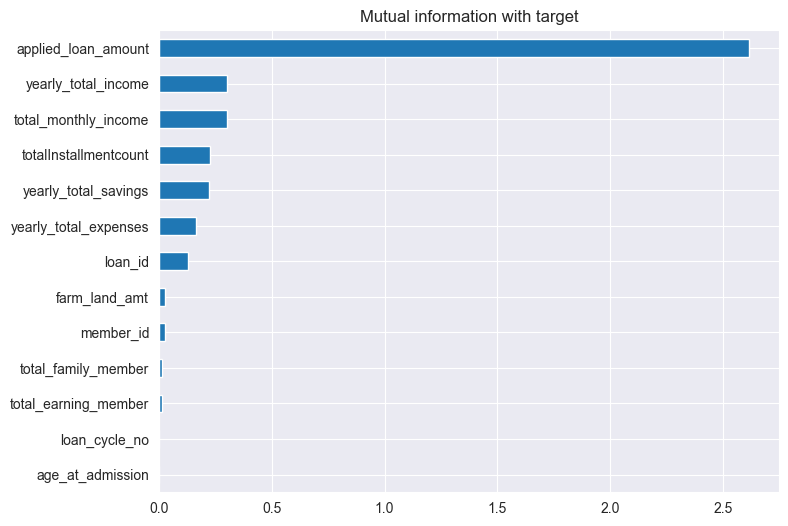

In [29]:
# NUMERIC FEATURES vs TARGET
# Pearson correlation measures the strength of a linear relationship. ( If a increase/decrease b should increase/decrease as same way or pause)
# Spearman correlation measures the strength of a monotonic relationship,
# meaning the variables consistently move in the same or opposite direction in rank order. ( increase/decrease to on another without measuring equal size or pause.
corr_rows = []
for c in num_cols:
    d = df[[c, 'loan_amount']].dropna()
    if len(d) > 10 and d[c].nunique() > 1:
        corr_rows.append([c, d[c].corr(d['loan_amount']), d[c].corr(d['loan_amount'], method="spearman")])
corr_df = pd.DataFrame(corr_rows, columns=["feature", "pearson", "spearman"])
corr_df = corr_df.reindex(corr_df.spearman.abs().sort_values(ascending=False).index)
print(corr_df.round(3).to_string(index=False))

# mutual information (captures non-linear)
X = df[num_cols].fillna(df[num_cols].median())
mi = mutual_info_regression(X, df['loan_amount'].fillna(df['loan_amount'].median()), random_state=0)
mi_s = pd.Series(mi, index=num_cols).sort_values(ascending=False)
print("\nMutual information with target:\n", mi_s.round(4))
mi_s.head(20).plot.barh(figsize=(8, 6)).invert_yaxis()
plt.title("Mutual information with target")

In [18]:
# top = corr_df.feature.head(8).tolist()
# fig, axes = plt.subplots(2, 4, figsize=(18, 8))
# for a, c in zip(axes.ravel(), top):
#     sns.scatterplot(data=df, x=c, y='loan_amount', alpha=.3, s=10, ax=a)
#     a.set_title(c, fontsize=9)

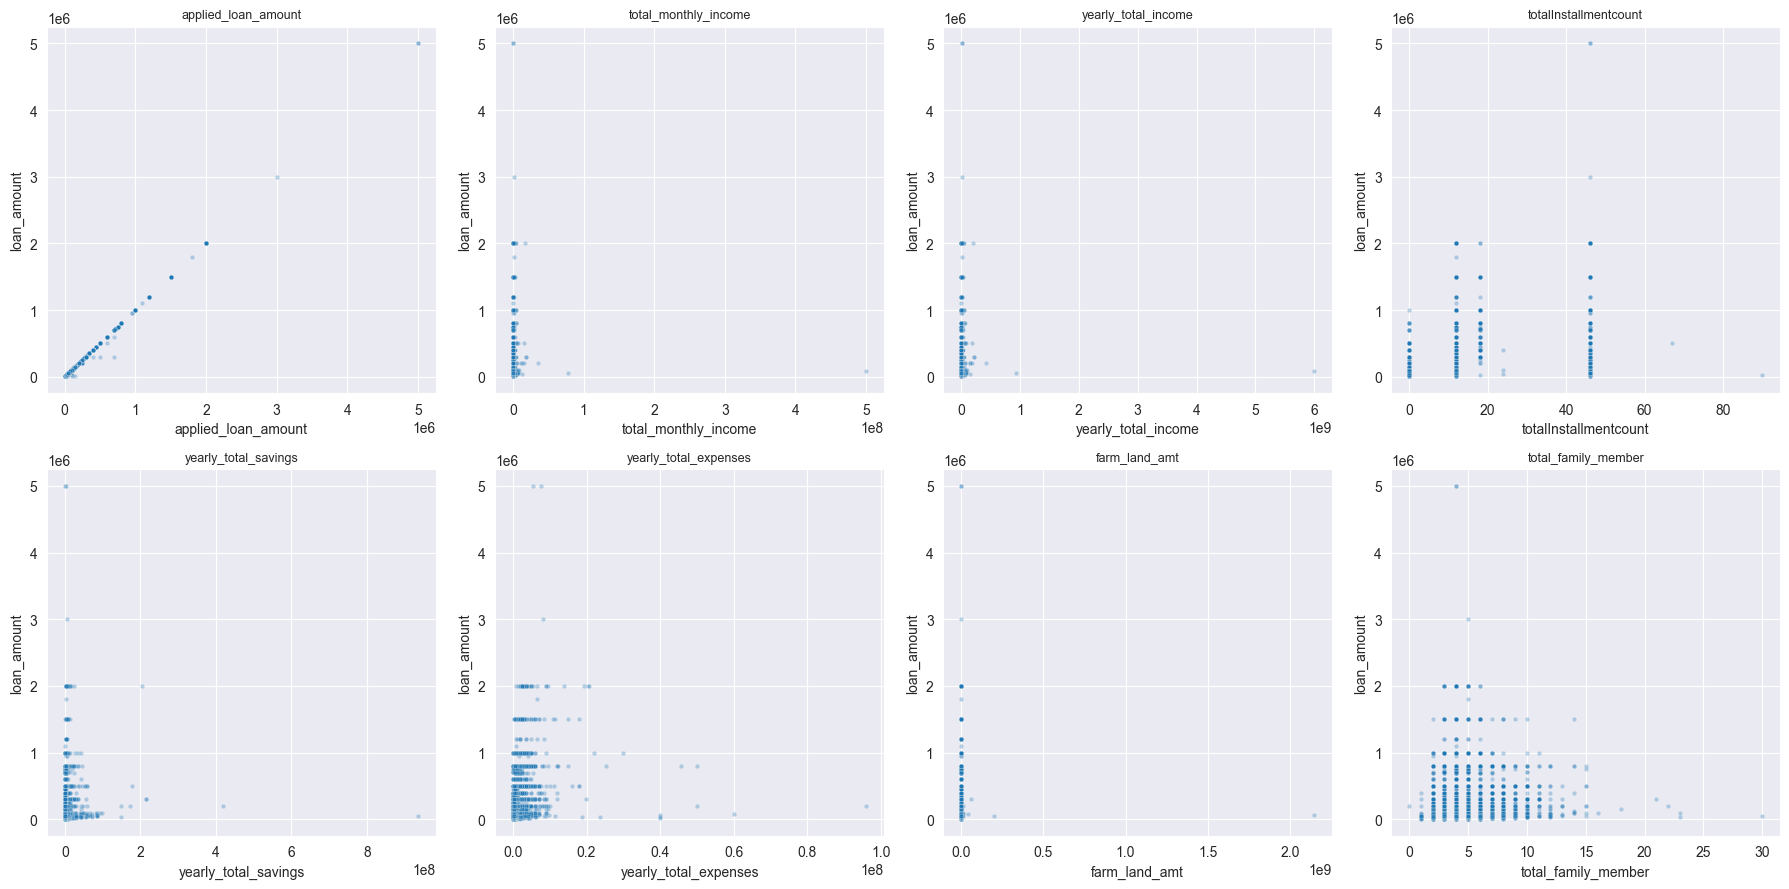

In [46]:
top = corr_df.feature.head(8).tolist()

cols = 4
rws = int(np.ceil(len(top) / cols))

fig, axes = plt.subplots(
    rws,
    cols,
    figsize=(18, 4.5 * rws)
)

axes = np.array(axes).reshape(rws, cols)

for a, c in zip(axes.ravel(), top):
    sns.scatterplot(
        data=df,
        x=c,
        y='loan_amount',
        alpha=.3,
        s=10,
        ax=a
    )
    a.set_title(c, fontsize=9)

for a in axes.ravel()[len(top):]:
    a.axis("off")

plt.tight_layout()
plt.show()


Text(0.5, 1.0, 'Spearman correlation')

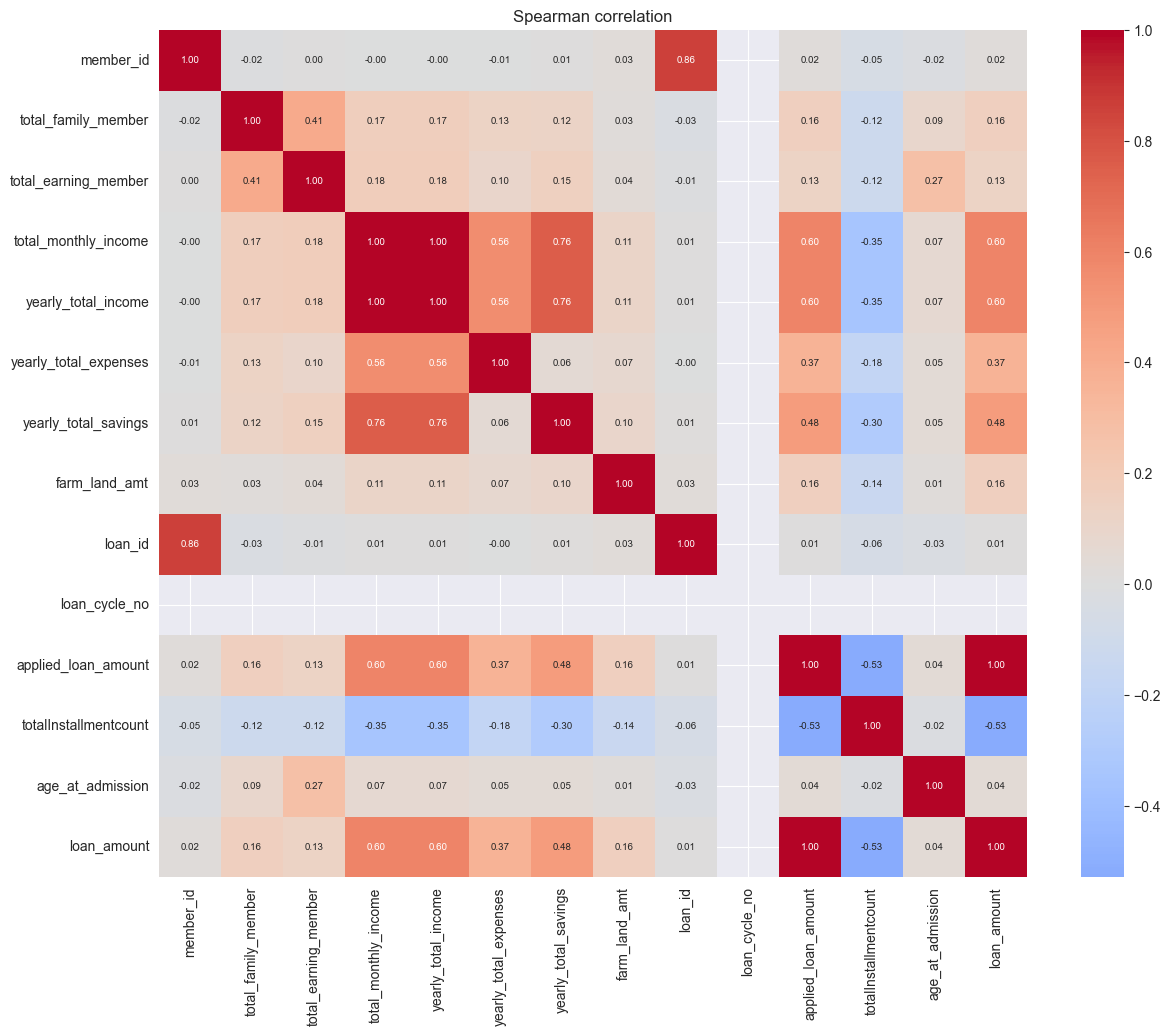

In [31]:
# correlation
cm = df[num_cols + ['loan_amount']].corr(method="spearman")
plt.figure(figsize=(14, 11))
sns.heatmap(cm, cmap="coolwarm", center=0, annot=len(cm) <= 20, fmt=".2f", annot_kws={"size": 7})
plt.title("Spearman correlation")

In [32]:
pairs = cm.abs().where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack()
print("Highly correlated pairs (|rho| > 0.85):")
print(pairs[pairs > .85].sort_values(ascending=False).round(3))

Highly correlated pairs (|rho| > 0.85):
total_monthly_income  yearly_total_income   1
applied_loan_amount   loan_amount           1
member_id             loan_id               1
dtype: float64


In [33]:
# MULTICOLLINEARITY
try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    v = X.replace([np.inf, -np.inf], np.nan).dropna()
    v = v.loc[:, v.std() > 0]
    vif = pd.Series([variance_inflation_factor(v.values, i) for i in range(v.shape[1])], index=v.columns)
    print("\nVIF (>10 = problematic):\n", vif.sort_values(ascending=False).round(1).head(15))
except Exception as e:
    print("VIF skipped:", e)


VIF (>10 = problematic):
 total_monthly_income    1,000,799,917,193,444
yearly_total_income     1,000,799,917,193,444
total_earning_member                        1
total_family_member                         1
applied_loan_amount                         1
totalInstallmentcount                       1
loan_id                                     1
member_id                                   1
yearly_total_expenses                       1
age_at_admission                            1
yearly_total_savings                        1
farm_land_amt                               1
dtype: float64


In [35]:
## Category VS Target
for c in cat_cols:
    d = df[[c, 'loan_amount']].dropna()
    g = d.groupby(c)['loan_amount'].agg(["count", "mean", "median", "std"]).sort_values("count", ascending=False)
    groups = [x['loan_amount'].values for _, x in d.groupby(c) if len(x) >= 5]
    if len(groups) >= 2:
        h, p = stats.kruskal(*groups)
        print(f"\n{c}: Kruskal-Wallis H={h:.1f}, p={p:.4g}")
    print(g.head(10).round(1))


gender: Kruskal-Wallis H=3383.5, p=0
         count    mean  median     std
gender                                
Female  111112  95,594  60,000  99,480
Male     12881 175,420  95,000 213,833

current_addr_district: Kruskal-Wallis H=17059.4, p=0
                       count    mean  median     std
current_addr_district                               
Chattogram              9096 108,297  70,000 118,242
Dinajpur                6903  70,459  50,000  82,982
Brahmanbaria            6052 135,299  80,000 132,407
Bhola                   5755 128,395 100,000 116,196
Mymensingh              5613 112,651  70,000 107,041
Rajshahi                4287  67,922  50,000  57,286
Patuakhali              4162  78,088  60,000  71,079
Barishal                3657  93,665  60,000  86,754
Rangpur                 3533  78,113  50,000  91,690
Jashore                 3295 110,654  80,000  91,440

current_addr_thana: Kruskal-Wallis H=21128.7, p=0
                    count    mean  median     std
current_addr_th

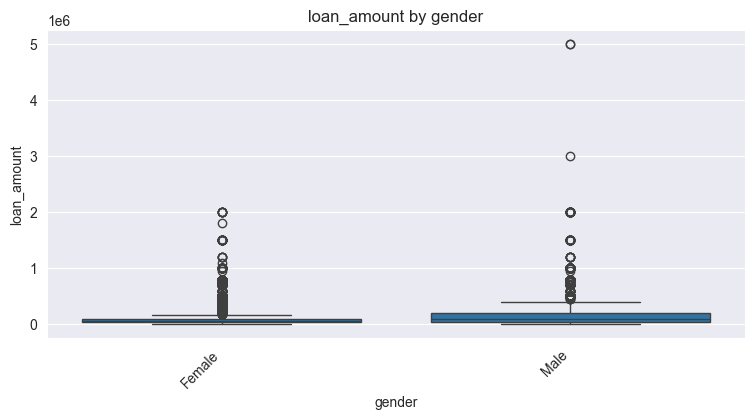

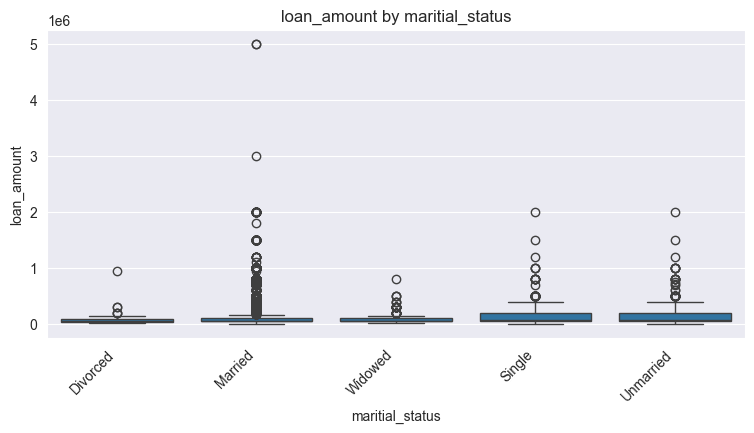

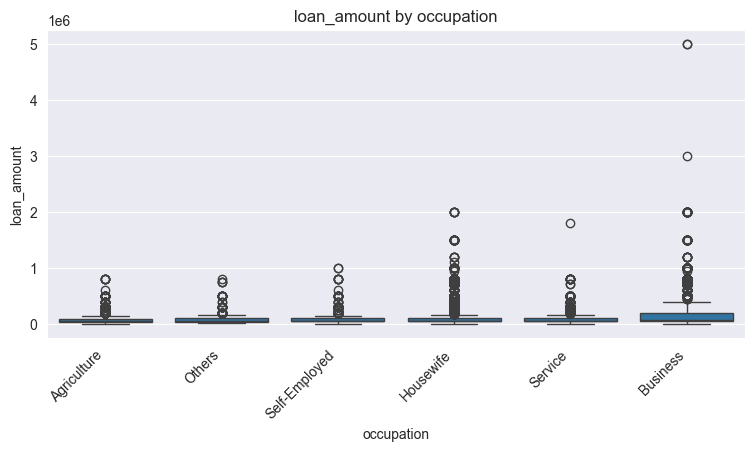

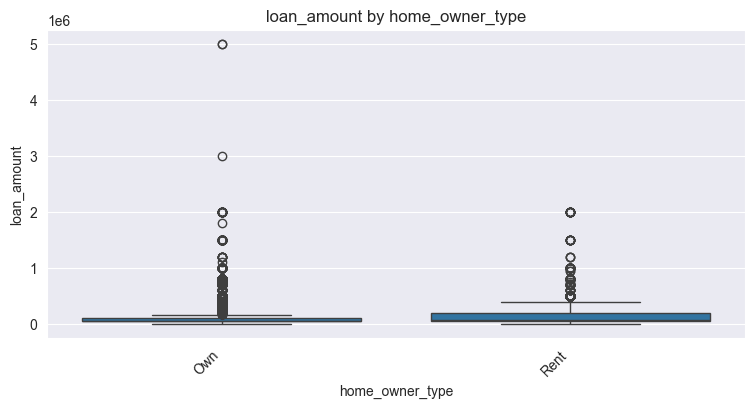

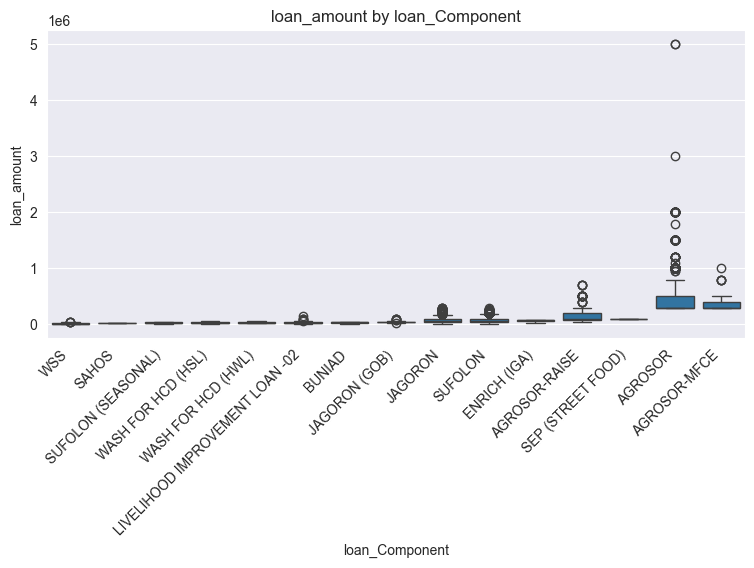

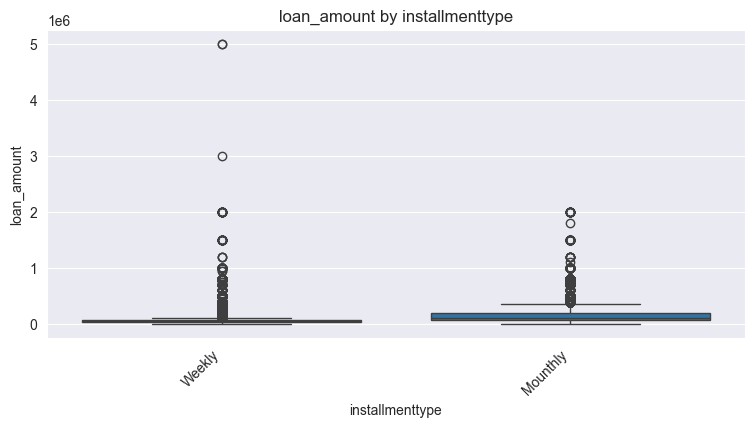

In [36]:
for c in low_card:
    plt.figure(figsize=(9, 4))
    order = df.groupby(c)['loan_amount'].median().sort_values().index
    sns.boxplot(data=df, x=c, y='loan_amount', order=order)
    plt.xticks(rotation=45, ha="right"); plt.title(f"{'loan_amount'} by {c}")


In [23]:
# df[df['current_addr_thana']=='Wari'].value_counts

In [26]:
# High cardinality geography
# for c in ["current_addr_district", "current_addr_thana"]:
#     if c in df:
#         g = df.groupby(c)['loan_amount'].agg(["count", "median"]).query("count >= 20").sort_values("median")
#         if len(g):
#             g["median"].plot.barh(figsize=(8, max(4, len(g) * .25)))
#             plt.title(f"Median {'loan_amount'} by {c} (n>=20)")

In [38]:
## Proposer or Referral Effect
if "proposer_oldid" in df:
    pc = df["proposer_oldid"].value_counts()
    print("Unique proposers:", len(pc), " | Top proposers:\n", pc.head(10))
    df["proposer_n_members"] = df["proposer_oldid"].map(pc)
    print("Corr proposer_n_members vs target:",
          round(df["proposer_n_members"].corr(df['loan_amount'], method="spearman"), 3))

Unique proposers: 3162  | Top proposers:
 proposer_oldid
0074720110     164
0197770124     163
0177251122     162
0203300524     154
0205520824     150
01782214454    147
0133301017     141
0172490822     138
0210011024     129
0136260218     128
Name: count, dtype: int64
Corr proposer_n_members vs target: -0.095


In [43]:
## Leakage & Correlation
print("applied_loan_amount vs loan_amount corr:",
      round(df["applied_loan_amount"].corr(df['loan_amount']), 3))
print("% where loan_amount == applied_loan_amount:",
      round((df['loan_amount'] == df["applied_loan_amount"]).mean() * 100, 1))
print("% approved > applied:", round((df['loan_amount'] > df["applied_loan_amount"]).mean() * 100, 1))


applied_loan_amount vs loan_amount corr: 1.0
% where loan_amount == applied_loan_amount: 100.0
% approved > applied: 0.0


In [44]:
for c in ["age_at_admission", "total_monthly_income", "total_family_member", "farm_land_amt"]:
    if c in df and df[c].nunique() > 5:
        b = pd.qcut(df[c], 5, duplicates="drop")
        print(f"\n{c}\n", df.groupby(b)['loan_amount'].agg(["count", "mean", "median"]).round(0))


age_at_admission
                   count    mean  median
age_at_admission                       
(12.999, 28.0]    26258 100,576  60,000
(28.0, 35.0]      24823 104,597  60,000
(35.0, 40.0]      26728  99,293  60,000
(40.0, 45.0]      21786 104,363  60,000
(45.0, 71.0]      24398 111,337  70,000

total_monthly_income
                         count    mean  median
total_monthly_income                         
(-0.001, 30000.0]       28424  49,794  50,000
(30000.0, 40000.0]      25359  61,521  50,000
(40000.0, 50000.0]      26040  80,959  70,000
(50000.0, 70000.0]      21257 113,361  96,000
(70000.0, 500001554.0]  22913 235,147 200,000

total_family_member
                      count    mean  median
total_family_member                       
(-0.001, 3.0]        39561  87,972  50,000
(3.0, 4.0]           52831 103,036  60,000
(4.0, 5.0]           23215 118,129  80,000
(5.0, 30.0]           8386 144,901  80,000

farm_land_amt
                       count    mean  median
farm_land_amt   

In [ ]:
#MI & VF Result

# income and land value, minimum age need to be fixed
# savings added no new information
# whitespace "year_of_rent" has “0” and “0 “ as separate values (116,701 and 3,297)
# alternative_occupation That gives 5,028 levels that should collapse to about 20  have krisi, farmer, agriculture, agriculter
# loan_use_sources has 244 levels with overlaps like house repairing, Home Repair, Fishery to Fish Business
# District spellings: Comilla and Cumilla, Kishoreganj and Kishoregonj.
# Education should merge like PSC with Primary and pre_primary mean dropout
# propser_id clean those ID_Nai
# totalInstallmentcount = 0 on 1801 rows this columns nearly deterministic from installmenttype, take one
# member_id, loan_id, loan_cycle_no, applied_loan_amount not useful
# 11% of income as outliers because income is right-skewed can use log scale or quantile caps instead
# check whether home_owner_type and alternative_occupation are missing because a field was added later

## deep
## Rule discovery: plot loan_amount / yearly_income by product. If the upper envelope is tight (for example a cap like 30–40% of income), you’ve found the policy rule, and a quantile model of that cap may beat a generic regressor
# Proposer and thana variance share: fit a mixed model or compute an out-of-fold target encoding. If it explains a lot, the model is learning officer habits, not borrower capacity

# Fairness: gender and geography are proxies in a lending context. Decide whether they should be excluded, and report errors by gender and district

# Thoughts on modeling
# use a time-based split (sort by loan_id or the dropped disbursed_date, train on the first 80%)
# CatBoost or LightGBM on log1p(loan_amount) with L1 or Huber objective
# CatBoost handles the high-cardinality thana, proposer and purpose columns natively

# Monthly income	Chance of a loan ≥300k
# 30k	                   0.2%
# 50k	                   1.8%
# 70k                  	11%
# 100k                	36%
# 150k                 	62%